In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import joblib
from google.colab import files

In [2]:
np.random.seed(42)
n_samples = 500

data = {
    'Age': np.random.randint(21, 65, size=n_samples),
    'Annual_Income': np.random.randint(25000000, 250000000, size=n_samples), # Rupiah
    'Credit_Score': np.random.randint(300, 850, size=n_samples),
    'Loan_Amount': np.random.randint(5000000, 120000000, size=n_samples),
    'Employment_Status': np.random.choice(['Pegawai Tetap', 'Kontrak', 'Wiraswasta', 'Belum Bekerja'], size=n_samples, p=[0.45, 0.25, 0.20, 0.10]),
    'Existing_Debt': np.random.randint(0, 40000000, size=n_samples)
}

df = pd.DataFrame(data)

def determine_approval(row):
    score = 0
    if row['Credit_Score'] >= 650: score += 2
    if row['Annual_Income'] >= row['Loan_Amount'] * 0.8: score += 2
    if row['Employment_Status'] == 'Pegawai Tetap': score += 2
    if row['Existing_Debt'] <= row['Annual_Income'] * 0.25: score += 1
    return 1 if score >= 4 else 0

df['Loan_Approved'] = df.apply(determine_approval, axis=1)

df.to_csv("credit_risk_dataset.csv", index=False)
print(" Dataset 'credit_risk_dataset.csv' berhasil dibuat!")
df.head()

 Dataset 'credit_risk_dataset.csv' berhasil dibuat!


,Age,Annual_Income,Credit_Score,Loan_Amount,Employment_Status,Existing_Debt,Loan_Approved
0,59,48151417,325,12393979,Wiraswasta,181360,0
1,49,64673332,734,15115078,Wiraswasta,19221242,1
2,35,178917041,472,33506244,Wiraswasta,19292635,0
3,63,41934380,599,30214698,Pegawai Tetap,5532410,1
4,28,35617244,625,107285868,Wiraswasta,4138286,0


In [3]:
df = pd.read_csv("credit_risk_dataset.csv")

le = LabelEncoder()
df['Employment_Status_Encoded'] = le.fit_transform(df['Employment_Status'])

X = df[['Age', 'Annual_Income', 'Credit_Score', 'Loan_Amount', 'Employment_Status_Encoded', 'Existing_Debt']]
y = df['Loan_Approved']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data preprocessing dan scaling fitur selesai!")
print(f"Bentuk Fitur (X): {X_scaled.shape}, Bentuk Target (y): {y.shape}")

Data preprocessing dan scaling fitur selesai!
Bentuk Fitur (X): (500, 6), Bentuk Target (y): (500,)


In [4]:
# Sel 4: Pembagian Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print(f"📊 Total Data Training (70%): {X_train.shape[0]} sampel")
print(f"📊 Total Data Testing (30%) : {X_test.shape[0]} sampel")

📊 Total Data Training (70%): 350 sampel
📊 Total Data Testing (30%) : 150 sampel


In [5]:
# Sel 5: Training Model ML
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit Model
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Model Decision Tree dan Random Forest selesai dilatih!")

Model Decision Tree dan Random Forest selesai dilatih!


=== HASIL EVALUASI MODEL RANDOM FOREST ===
Accuracy  : 95.33%
Precision : 97.62%
Recall    : 94.25%
F1-Score  : 95.91%

Classification Report:
                   precision    recall  f1-score   support

 Ditolak (Risiko)       0.92      0.97      0.95        63
Disetujui (Layak)       0.98      0.94      0.96        87

         accuracy                           0.95       150
        macro avg       0.95      0.96      0.95       150
     weighted avg       0.95      0.95      0.95       150



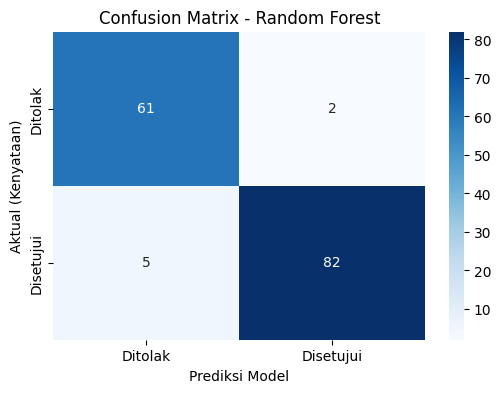

In [6]:
y_pred_rf = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred_rf)
prec = precision_score(y_test, y_pred_rf)
rec = recall_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)

print("=== HASIL EVALUASI MODEL RANDOM FOREST ===")
print(f"Accuracy  : {acc * 100:.2f}%")
print(f"Precision : {prec * 100:.2f}%")
print(f"Recall    : {rec * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Ditolak (Risiko)', 'Disetujui (Layak)']))

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ditolak', 'Disetujui'],
            yticklabels=['Ditolak', 'Disetujui'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual (Kenyataan)')
plt.show()

In [7]:
# Sel 7: Ekspor Model dan Unduh Otomatis
joblib.dump(rf_model, "credit_risk_model.pkl")
joblib.dump(scaler, "scaler.pkl")

files.download("credit_risk_dataset.csv")
files.download("credit_risk_model.pkl")
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>